# 02 — So sánh hàm mục tiêu MSE, MAE, Huber (RQ2)

**Câu hỏi:** hàm mục tiêu (MSE, MAE, Huber) ảnh hưởng thế nào đến sai số test tại nghiệm tối ưu, và mức bền vững với outlier ra sao? Tương ứng mục 4.2 của báo cáo (`report/`).

**Dữ liệu** (chỉ đọc, xem `results/README.md`):
- B3: `results/huber_mad/results_v2.csv` (MSE, MAE từ grid; Huber δ_MAD), `results/results_v2.csv` (Huber δ = 1).
- Outlier: `results/outliers/results_v2.csv`, `results/huber_mad/outliers/results_v2.csv`, `results/outliers_mag/results_v2.csv`.
- Độ nhạy theo δ: `results/nv7/summary.json`.

Mọi phép tính dùng `scripts/report/report_data.py`, hình dùng `scripts/report/make_figures.py`, nên số và hình ở đây trùng báo cáo LaTeX. Tiêu chí λ\*: MSE test ở λ\*_MSE (argmin MSE val), MAE test ở λ\*_MAE (argmin MAE val).

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent                     # chạy với thư mục làm việc là notebooks/
sys.path[:0] = [str(ROOT / "scripts" / "report")]
import report_data as D                      # đọc results/ (không ghi gì)
import make_figures as F                     # cùng hàm vẽ với báo cáo LaTeX
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

## B3: sai số test tại nghiệm tối ưu của ba mục tiêu

In [2]:
rows = []
for ds, H, m in D.cells():
    r = {"dataset": ds, "H": H, "model": m}
    for met in D.METRICS:
        for ob in D.OBJECTIVES:
            r[f"{met.upper()} test | {ob}"] = D.b3(ds, H, m, ob, met)
    rows.append(r)
b3 = pd.DataFrame(rows).set_index(["dataset", "H", "model"])

def bold_min(df, cols):
    s = pd.DataFrame("", index=df.index, columns=df.columns)
    for c in cols:
        sub = df[c]
        s.loc[:, c] = sub.eq(sub.min(axis=1), axis=0).replace({True: "font-weight: bold", False: ""})
    return s

groups = [[c for c in b3.columns if c.startswith(p)] for p in ("MSE test", "MAE test")]
display(b3.style.apply(lambda df: bold_min(df, groups), axis=None).format("{:.4f}"))

## MAE so với MSE: MSE test(MSE) − MSE test(MAE) theo H (dương: MAE tốt hơn)

In [3]:
gain = pd.DataFrame({(ds, m): D.mae_minus_mse_gain(ds, m) for ds in D.DATASETS for m in D.MODELS},
                    index=D.HORIZONS).T
gain["số H MAE tốt hơn"] = (gain[D.HORIZONS] > 0).sum(axis=1)
display(gain.style.format("{:.4f}", subset=D.HORIZONS))
print("Tổng số ô MAE cho MSE test thấp hơn MSE:", int(gain["số H MAE tốt hơn"].sum()), "/ 36")

Tổng số ô MAE cho MSE test thấp hơn MSE: 30 / 36


## Vị trí của Huber, và δ_MAD so với δ = 1

In [4]:
for met in D.METRICS:
    print(f"{met.upper()} test — mục tiêu tốt nhất:", D.best_counts(met), "| hạng của Huber:", D.huber_rank_counts(met))
for met in D.METRICS:
    better = sum(D.b3(*k, "Huber", met) < D.b3(*k, "Huber", met, huber="one") for k in D.cells())
    print(f"Huber δ_MAD tốt hơn δ = 1 theo {met.upper()} test: {better}/36 ô")
deltas = pd.Series({k: D.b3_delta(*k) for k in D.cells()})
print("δ_MAD: min %.3f, trung vị %.3f, max %.3f" % (deltas.min(), deltas.median(), deltas.max()))

MSE test — mục tiêu tốt nhất: {'MSE': 5, 'MAE': 24, 'Huber': 7} | hạng của Huber: {1: 7, 2: 28, 3: 1}
MAE test — mục tiêu tốt nhất: {'MSE': 1, 'MAE': 33, 'Huber': 2} | hạng của Huber: {1: 2, 2: 34, 3: 0}
Huber δ_MAD tốt hơn δ = 1 theo MSE test: 27/36 ô
Huber δ_MAD tốt hơn δ = 1 theo MAE test: 34/36 ô
δ_MAD: min 0.372, trung vị 0.537, max 0.731


## H4: độ nhạy của Huber theo δ

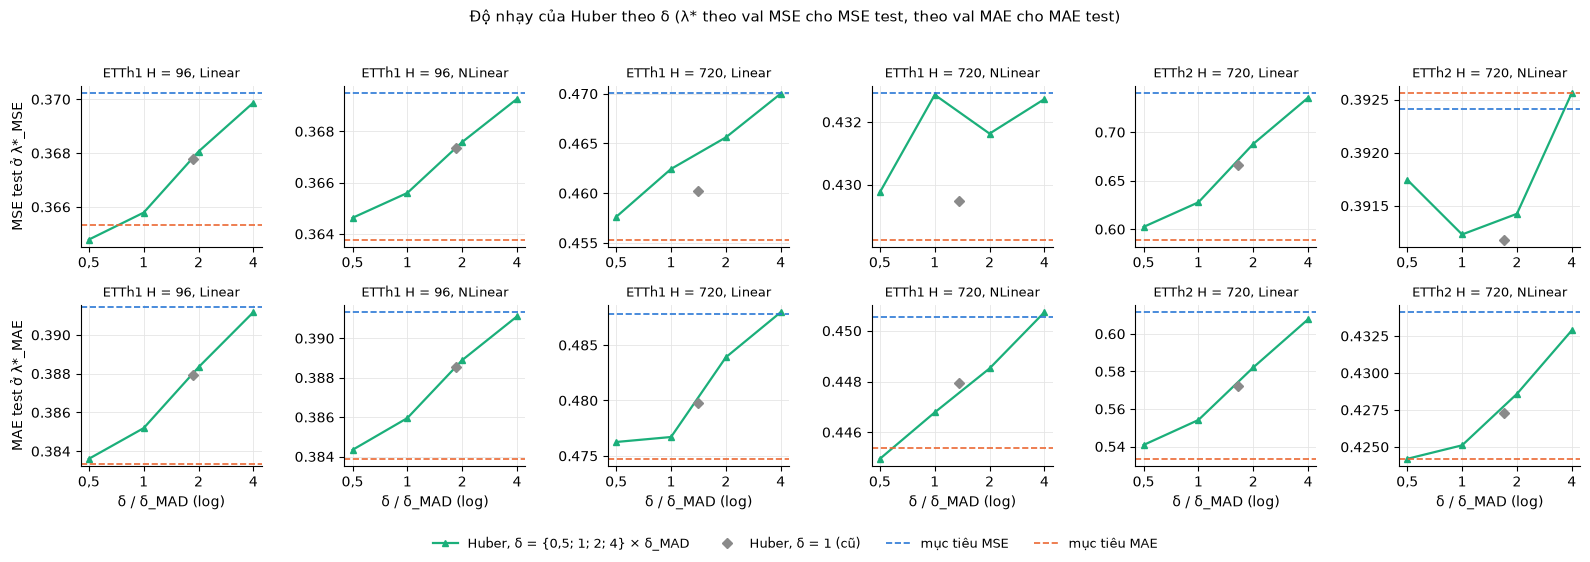

In [5]:
for png in F.capture_png(F.h4):
    display(Image(png))

## H2: outlier nhân tạo (ETTh1, ±10 độ lệch chuẩn, seed 2026)

Nét liền: chèn vào chuỗi; nét đứt: chèn chỉ vào đích. Hình đầu theo MSE test, hình sau theo MAE test.

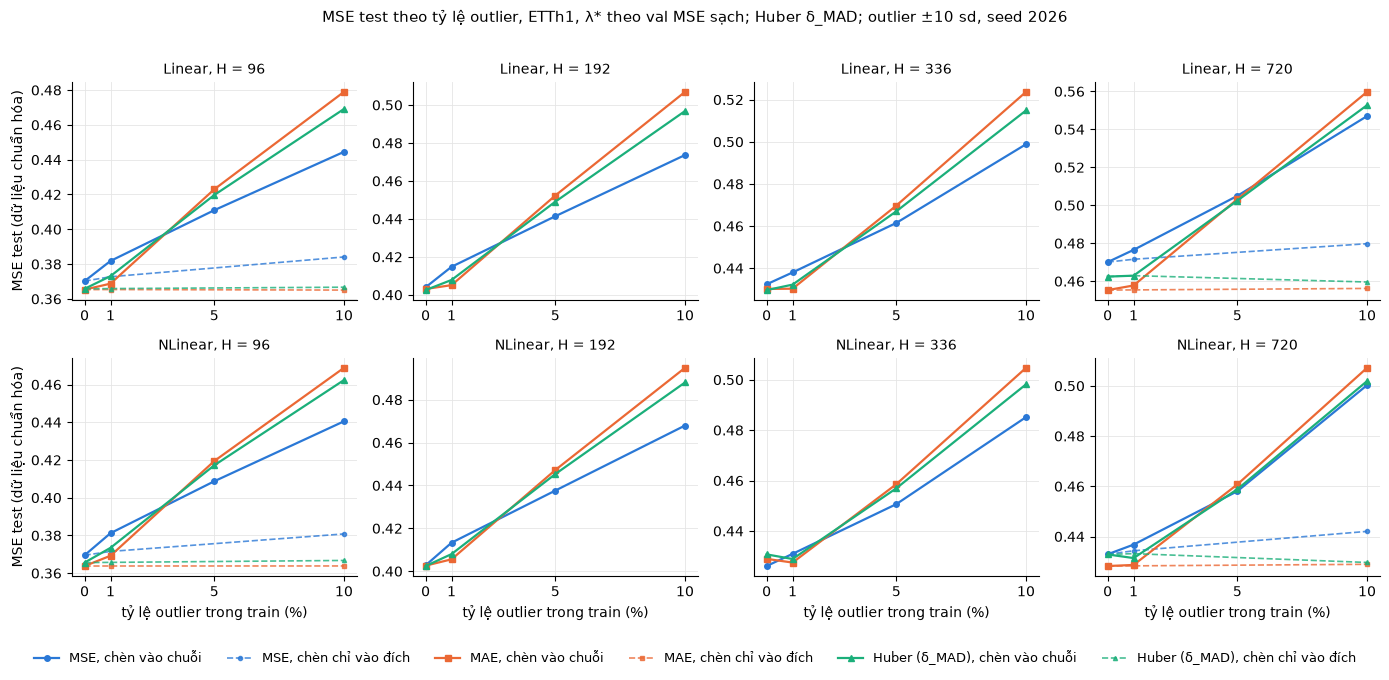

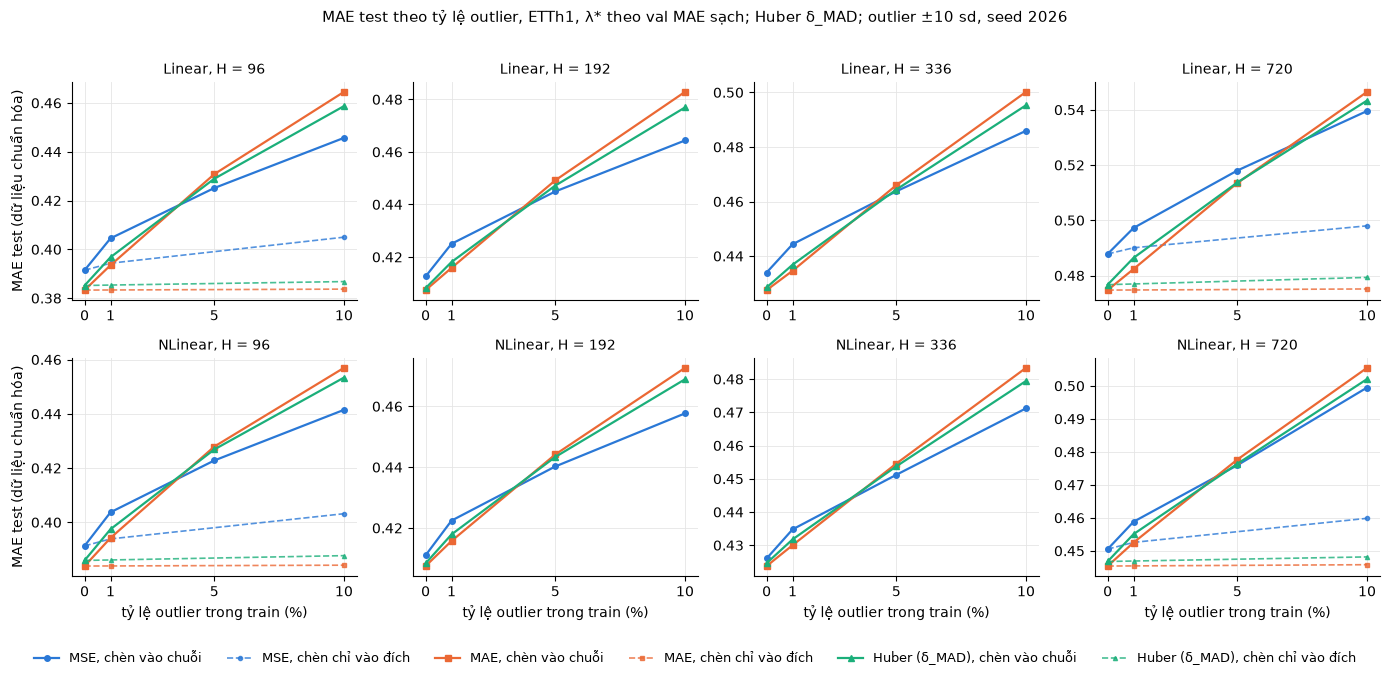

In [6]:
for png in F.capture_png(F.h2):
    display(Image(png))

In [7]:
rows = []
for m in ("Linear", "NLinear"):
    for H in D.HORIZONS:
        for mode, rate in [("series", 0)] + [("series", r) for r in (0.01, 0.05, 0.1)] + \
                          ([("target", r) for r in (0.01, 0.1)] if H in (96, 720) else []):
            r = {"model": m, "H": H, "chèn": "gốc" if rate == 0 else mode, "rate": rate}
            for ob in D.OBJECTIVES:
                r[f"MSE test | {ob}"] = D.outlier(mode, rate, H, m, ob, "mse")
            rows.append(r)
out = pd.DataFrame(rows)
out["tốt nhất"] = out[[f"MSE test | {o}" for o in D.OBJECTIVES]].idxmin(axis=1).str.replace("MSE test | ", "")
display(out)

,model,H,chèn,rate,MSE test | MSE,MSE test | MAE,MSE test | Huber,tốt nhất
0,Linear,96,gốc,0.00,0.3702,0.3653,0.3658,MAE
1,Linear,96,series,0.01,0.3818,0.3688,0.3731,MAE
2,Linear,96,series,0.05,0.4110,0.4230,0.4197,MSE
3,Linear,96,series,0.10,0.4445,0.4790,0.4691,MSE
4,Linear,96,target,0.01,0.3727,0.3654,0.3659,MAE
5,Linear,96,target,0.10,0.3841,0.3651,0.3667,MAE
6,Linear,192,gốc,0.00,0.4040,0.4031,0.4025,Huber
7,Linear,192,series,0.01,0.4148,0.4051,0.4078,MAE
8,Linear,192,series,0.05,0.4414,0.4523,0.4491,MSE
9,Linear,192,series,0.10,0.4736,0.5069,0.4968,MSE


## H5: độ lớn outlier (Linear, ETTh1, seed 2026)

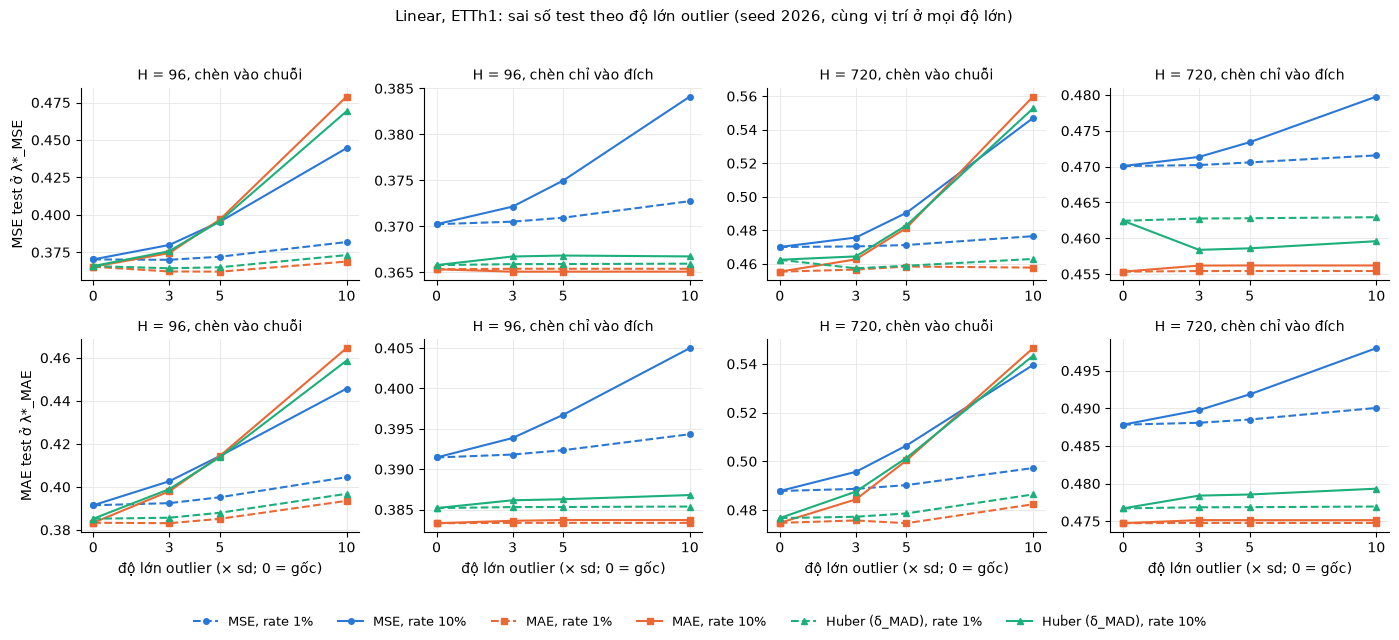

In [8]:
for png in F.capture_png(F.h5):
    display(Image(png))